# 03 · EDA univariado: series de tiempo con las herramientas del curso

**Términos que se usan en todo el notebook:** [retorno](../docs/entrega_1/glosario.md) (variación relativa entre dos precios seguidos; se usa el [log-retorno](../docs/entrega_1/glosario.md) r = ln(P_t / P_{t-1}) porque suma a través del tiempo), [volatilidad](../docs/entrega_1/glosario.md) (desviación de los retornos; mide cuánto se mueve el precio), [drawdown](../docs/entrega_1/glosario.md) (caída desde el máximo previo), [percentil](../docs/entrega_1/glosario.md) (posición de un valor dentro de su propia historia), [bootstrap por bloques](../docs/entrega_1/glosario.md) (remuestreo de tramos consecutivos; conserva la dependencia en el tiempo), [IC](../docs/entrega_1/glosario.md) (intervalo de confianza), [sesión turbulenta](../docs/entrega_1/glosario.md) (día con |retorno| en el 20 % superior de la historia previa del ticker), [look-ahead](../docs/entrega_1/glosario.md) (usar en t un dato posterior a t) y [SPY](../docs/entrega_1/glosario.md) y [XLP](../docs/entrega_1/glosario.md) (ETF del mercado estadounidense y del sector de consumo defensivo).

**Objetivo.** EDA univariado (gráfico y no gráfico) de las 23 series diarias y semanales de la industria piloto, con dos preguntas de negocio contestadas con la plantilla del profesor: **P1** (¿cuánto me puede doler una semana?) y **P6** (¿vienen juntas las sesiones turbulentas?). Las dos usan [bootstrap por bloques](../docs/entrega_1/glosario.md) porque las observaciones no son independientes.

**Punto del enunciado que cubre.** Punto 6 (EDA y calidad de datos). Es la rama de riesgo (P1) y de agrupamiento de turbulencia (P6); la fundamental (P2, P3), la técnica (P4) y la del sector (P5) se trabajan en el nb04.

**Qué alimenta.** `data/resultados/nb03.json` con las 5 pruebas de este notebook y los IC que sostienen cada decisión; el nb04 lo lee en su §8.

**Equivalencia pregunta → sección:**

| Pregunta | Sección | Frecuencia |
|---|---|---|
| P1: riesgo semanal | §4 | semanal |
| P6: turbulencia agrupada | §5 | diaria (principal) y semanal (robustez) |

**Base teórica:** `.docs/research/series_tiempo_curso.md`.

In [1]:
import json, sys, time, warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
sys.path.insert(0, "."); import comunes as cm      # nbconvert ejecuta el kernel en notebooks/, donde está comunes.py
sns.set_theme(style="whitegrid"); pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.width", 200); pd.set_option("display.max_rows", 200)

# Constantes del notebook (qué significan y por qué ese valor: docs/entrega_1/04_enfoque_analitico.md §4.5)
VENT_VOL_SEM = 52            # semanas: ventana de la volatilidad móvil anualizada (un año bursátil)
VENT_VOL_DIA = 252           # días hábiles: ventana equivalente de 52 semanas, en frecuencia diaria
UMBRAL_Z_P1 = 2.0            # z < -2: convención de caída fuerte (una normal daría ~1 de cada 40 semanas)
BLOQUE_SEM = 12              # bloque del bootstrap semanal (un trimestre); 4 y 26 son sensibilidad
BLOQUE_DIA = 60              # bloque del bootstrap diario (un trimestre de días); 20 y 120 son sensibilidad
REPS_BOOT = 1000             # réplicas del bootstrap (el curso usa 1000; percentiles al 95 % ya estables)
REPS_NULO = 2000             # réplicas de la simulación del nulo calibrado de P1
MIN_HIST_SEM = 104           # semanas: dos años mínimos para calibrar el percentil 80 "turbulenta" semanal
MIN_HIST_DIA = 504           # días: dos años mínimos para calibrar el percentil 80 "turbulenta" diario
UMBRAL_P1 = 1.5              # P1: umbral = 1,5 × nulo (spec §5.5)
UMBRAL_P6 = 0.30             # P6: límite inferior del IC de P(T|T) para ser accionable (spec §5.5)
SUBPERIODOS = {              # tramos fijos: salida de 2008, expansión, COVID y mercado bajista 2022+
    "2009-2012": ("2009-01-01", "2012-12-31"),
    "2013-2019": ("2013-01-01", "2019-12-31"),
    "2020-2021": ("2020-01-01", "2021-12-31"),
    "2022+":     ("2022-01-01", "2099-12-31"),
}
RNG_SEMILLA = 42             # semilla reproducible; la misma que usa comunes.py

print("Constantes cargadas; UMBRAL_P1 =", UMBRAL_P1, "× nulo; UMBRAL_P6 =", UMBRAL_P6)

Constantes cargadas; UMBRAL_P1 = 1.5 × nulo; UMBRAL_P6 = 0.3


## 0.1 Carga de datos y log-retornos

Las instantáneas de `01_recoleccion.ipynb` vienen en formato largo (fecha, ticker, close, volume). Las paso a ancho (una columna por ticker), filtro al universo de la industria piloto más SPY y XLP (si una instantánea vieja no los trae, falla rápido con `KeyError`) y calculo los log-retornos. **Por qué log-retornos:** r = ln(P_t / P_{t-1}) se suma a través del tiempo (la §0.4 lo demuestra con un ejemplo), tiene escala comparable entre tickers y distribución casi simétrica, al contrario del precio.

In [2]:
acciones = cm.tickers()
mercado_sector = [cm.BENCHMARK, "XLP"]
columnas = acciones + mercado_sector

sem = cm.a_ancho(cm.cargar_snapshot("precios_semanales"))[columnas]
dia = cm.a_ancho(cm.cargar_snapshot("precios_diarios"))[columnas]
R = np.log(sem).diff()      # log-retornos semanales
Rd = np.log(dia).diff()     # log-retornos diarios

n_sem = R[acciones].notna().sum().median()
n_dia = Rd[acciones].notna().sum().median()
print(f"semanales: {R.shape[0]} semanas × {R.shape[1]} tickers; mediana de semanas por empresa: {int(n_sem)}")
print(f"diarios:   {Rd.shape[0]} sesiones × {Rd.shape[1]} tickers; mediana de sesiones por empresa: {int(n_dia)}")
print(f"rango semanal: {R.index.min().date()} a {R.index.max().date()}")

semanales: 928 semanas × 23 tickers; mediana de semanas por empresa: 927
diarios:   4474 sesiones × 23 tickers; mediana de sesiones por empresa: 4473
rango semanal: 2009-01-05 a 2026-10-12


## 0.2 Funciones de este notebook

Son las funciones que **solo** usa el nb03. Lo que varios notebooks comparten (universo, carga de instantáneas, bootstrap) vive en `comunes.py`.

In [3]:
def vol_movil(r, ventana=VENT_VOL_SEM, periodos=VENT_VOL_SEM):
    """Volatilidad móvil anualizada: desviación de las `ventana` observaciones hasta t (no mira al futuro)."""
    return r.rolling(ventana, min_periods=ventana).std(ddof=1) * np.sqrt(periodos)


def max_drawdown(close):
    """Caída máxima desde el máximo previo; devuelve (peor caída en proporción, serie de caídas)."""
    serie = close / close.cummax() - 1
    return float(serie.min()), serie


def percentil_retorno(r, q=0.05):
    """Percentil del retorno; con q=0,05 es la semana 'mala' de 1 en 20."""
    return float(np.nanquantile(r, q))


def tasa_caidas_fuertes(r, k=UMBRAL_Z_P1, ventana=VENT_VOL_SEM):
    """Fracción de observaciones con caída mayor que k veces la volatilidad de las `ventana` ANTERIORES.

    La volatilidad se calcula con `shift(1)` para no usar la observación de hoy en el umbral de hoy.
    """
    z = (r / r.rolling(ventana, min_periods=ventana).std(ddof=1).shift(1)).dropna()
    return float((z < -k).mean()) if len(z) else float("nan")


def nulo_caidas_fuertes(n, k=UMBRAL_Z_P1, ventana=VENT_VOL_SEM, reps=REPS_NULO, semilla=RNG_SEMILLA):
    """Nulo calibrado de P1: la tasa que daría `tasa_caidas_fuertes` si los retornos fueran normales i.i.d.

    Con σ estimada (no la verdadera) la tasa supera Φ(-2) = 2,275 %: ese Φ supone σ conocida.
    Este nulo es la comparación justa con la misma receta aplicada a la observación real.
    """
    rng = np.random.default_rng(semilla)
    return float(np.mean([tasa_caidas_fuertes(pd.Series(rng.standard_normal(n)), k, ventana) for _ in range(reps)]))


def chi2_cramer(x, y):
    """Chi-cuadrado de independencia + V de Cramér + residuos estandarizados (O - E)/√E.

    Con observaciones dependientes el p-value es optimista; la decisión la toma el IC por bloques.
    V de Cramér = tamaño de efecto, casi no depende de n (sirve para comparar frecuencias).
    """
    tabla = pd.crosstab(x, y)
    chi2, p, gl, esp = stats.chi2_contingency(tabla, correction=False)
    esp = pd.DataFrame(esp, index=tabla.index, columns=tabla.columns)
    v = float(np.sqrt(chi2 / (tabla.to_numpy().sum() * (min(tabla.shape) - 1))))
    return {"tabla": tabla, "esperados": esp,
            "residuos": (tabla - esp) / np.sqrt(esp),
            "chi2": float(chi2), "p": float(p), "gl": int(gl),
            "v_cramer": v, "min_esperado": float(esp.to_numpy().min())}


print("Funciones listas:", ["vol_movil", "max_drawdown", "percentil_retorno",
                             "tasa_caidas_fuertes", "nulo_caidas_fuertes", "chi2_cramer"])

Funciones listas: ['vol_movil', 'max_drawdown', 'percentil_retorno', 'tasa_caidas_fuertes', 'nulo_caidas_fuertes', 'chi2_cramer']


### 0.2.1 Comprobación de la receta del nulo calibrado

Simulo retornos normales i.i.d. del mismo tamaño que una empresa típica y le aplico la **misma** receta de la tasa de caídas fuertes. El resultado se compara con **Φ(−2) = 2,275 %** (lo que daría la fórmula con la σ verdadera). Es solo una demostración didáctica; el nulo del paso 0 de P1 se calcula con 2000 réplicas en §4.

In [4]:
demo = nulo_caidas_fuertes(n=900, reps=300)
phi_m2 = float(stats.norm.cdf(-UMBRAL_Z_P1))
print(f"nulo calibrado (demo, 300 réplicas, n=900): {demo:.4f}")
print(f"Φ(-2) teórico (σ verdadera):               {phi_m2:.4f}")
print(f"La diferencia viene de que σ se ESTIMA; con n finito la tasa de la receta supera Φ(-2).")

nulo calibrado (demo, 300 réplicas, n=900): 0.0251
Φ(-2) teórico (σ verdadera):               0.0228
La diferencia viene de que σ se ESTIMA; con n finito la tasa de la receta supera Φ(-2).


## 0.3 Por qué retornos y qué cambia al analizar series de tiempo

Hay 5 propiedades que justifican el enfoque. El **texto completo** vive en `docs/entrega_1/04_enfoque_analitico.md` §4.0; aquí doy la **evidencia** con cifras y gráficos. Fuentes: FPP3 (Hyndman y Athanasopoulos), Granger y Newbold (1974, "Spurious regressions") y Politis y Romano (1994, "The stationary bootstrap").

### 0.3.1 Estacionariedad aproximada: precios cambian de escala, retornos no

Boxplots del **precio** frente al **log-retorno semanal** de KO, WMT y TSN por los 4 subperíodos. El precio cambia de escala (la mediana del último tramo frente al primero crece varias veces), mientras que el log-retorno se mueve siempre alrededor de 0.

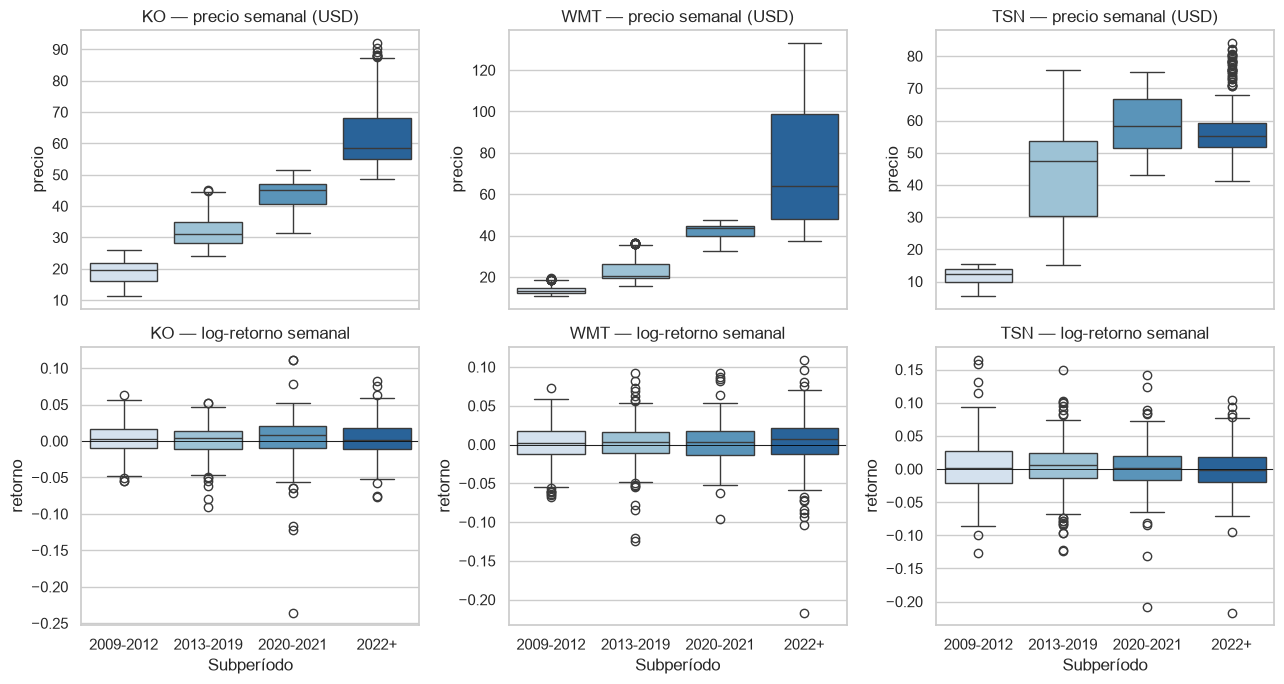

        precio_2022+/2009-12  retorno_2022+-2009-12
ticker                                             
KO                    2.9667                -0.0007
WMT                   4.9338                 0.0051
TSN                   4.4421                -0.0027


In [5]:
mu_tickers = ["KO", "WMT", "TSN"]
subs = SUBPERIODOS

def _marcar_sub(idx):
    s = pd.Series(index=idx, dtype=object)
    for nombre, (ini, fin) in subs.items():
        s.loc[(idx >= ini) & (idx <= fin)] = nombre
    return s

fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True)
for j, t in enumerate(mu_tickers):
    sub_sem = pd.DataFrame({"precio": sem[t], "retorno": R[t], "sub": _marcar_sub(sem.index)}).dropna()
    sns.boxplot(data=sub_sem, x="sub", y="precio", ax=axes[0, j],
                order=list(subs), hue="sub", palette="Blues", legend=False)
    axes[0, j].set_title(f"{t} — precio semanal (USD)"); axes[0, j].set_xlabel("")
    sns.boxplot(data=sub_sem, x="sub", y="retorno", ax=axes[1, j],
                order=list(subs), hue="sub", palette="Blues", legend=False)
    axes[1, j].set_title(f"{t} — log-retorno semanal"); axes[1, j].axhline(0, color="black", lw=0.6)
    axes[1, j].set_xlabel("Subperíodo")
plt.tight_layout(); fig.savefig(cm.DIR_ASSETS / "nb03_estacionariedad_subperiodos.png", dpi=120); plt.show()

# Razón entre la mediana del último tramo y la del primero
filas = []
for t in mu_tickers:
    g = pd.DataFrame({"precio": sem[t], "retorno": R[t], "sub": _marcar_sub(sem.index)}).dropna()
    med = g.groupby("sub", observed=True)[["precio", "retorno"]].median().reindex(list(subs))
    filas.append({"ticker": t, "precio_2022+/2009-12": med.loc["2022+", "precio"] / med.loc["2009-2012", "precio"],
                  "retorno_2022+-2009-12": med.loc["2022+", "retorno"] - med.loc["2009-2012", "retorno"]})
tabla = pd.DataFrame(filas).set_index("ticker"); print(tabla.round(4))

**Lectura (2–4 frases con cifras).** Para KO, WMT y TSN la mediana del precio del tramo 2022+ es varias veces la del tramo 2009–12 (la tabla imprime la razón); la del log-retorno queda cerca de 0 en todos los tramos (la diferencia absoluta es de milésimas). El precio no cumple la estacionariedad aproximada que suponen las herramientas del curso; el retorno sí, por eso toda la inferencia se hace sobre retornos.

### 0.3.2 Independencia relativa: la dirección casi no se repite; la magnitud sí

Scatter de r_t frente a r_{t−1} y de |r_t| frente a |r_{t−1}| en frecuencia **diaria** para 3 tickers. Además, la **correlación de 1 rezago** en semanal (mediana de las 21 empresas) para precio, retorno y |retorno|: el precio tiene correlación cercana a 1 (tendencia), el retorno es casi 0 y la |magnitud| sí es positiva (agrupamiento de volatilidad).

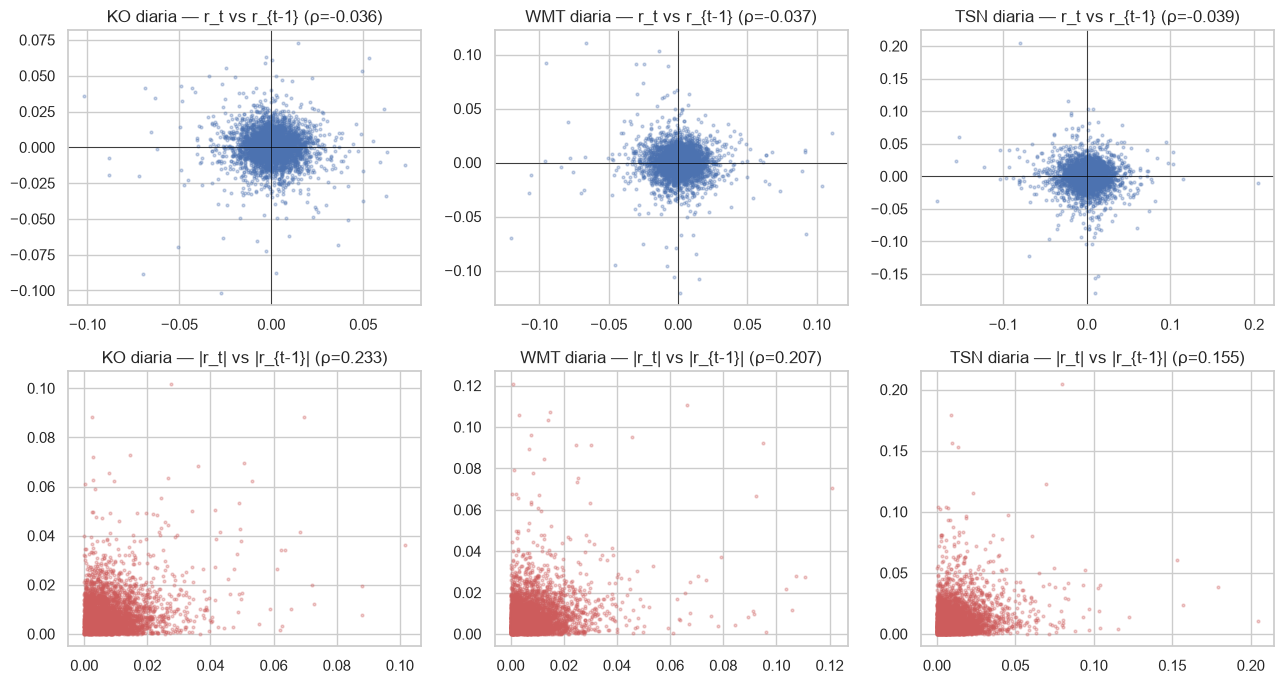

Correlación a 1 rezago (semanal) — mediana de las 21 empresas:
         precio  retorno  |retorno|
mediana  0.9977  -0.0500     0.1293


In [6]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for j, t in enumerate(mu_tickers):
    r_t = Rd[t].dropna(); r_lag = r_t.shift(1); d = pd.DataFrame({"r_t": r_t, "r_lag": r_lag}).dropna()
    axes[0, j].scatter(d.r_lag, d.r_t, s=4, alpha=0.3)
    axes[0, j].set_title(f"{t} diaria — r_t vs r_{{t-1}} (ρ={d.corr().iloc[0,1]:.3f})")
    axes[0, j].axhline(0, color="black", lw=0.5); axes[0, j].axvline(0, color="black", lw=0.5)
    da = pd.DataFrame({"abs_t": r_t.abs(), "abs_lag": r_lag.abs()}).dropna()
    axes[1, j].scatter(da.abs_lag, da.abs_t, s=4, alpha=0.3, color="indianred")
    axes[1, j].set_title(f"{t} diaria — |r_t| vs |r_{{t-1}}| (ρ={da.corr().iloc[0,1]:.3f})")
plt.tight_layout(); fig.savefig(cm.DIR_ASSETS / "nb03_dependencia_scatter.png", dpi=120); plt.show()

filas = []
for t in acciones:
    s_p = sem[t].dropna(); s_r = R[t].dropna()
    rho_p = s_p.autocorr(1) if len(s_p) > 10 else np.nan
    rho_r = s_r.autocorr(1) if len(s_r) > 10 else np.nan
    rho_a = s_r.abs().autocorr(1) if len(s_r) > 10 else np.nan
    filas.append({"ticker": t, "precio": rho_p, "retorno": rho_r, "|retorno|": rho_a})
corr1 = pd.DataFrame(filas).set_index("ticker")
print("Correlación a 1 rezago (semanal) — mediana de las 21 empresas:")
print(corr1.median().round(4).to_frame("mediana").T)

**Lectura.** La mediana de la correlación a 1 rezago del precio semanal se acerca a 1 (tendencia pura), la del retorno queda cerca de 0 (la dirección casi no se repite) y la de |retorno| es positiva pero más baja (agrupamiento de volatilidad: tras una semana movida es más probable otra movida). Es la base de la §5 (P6): se agrupa la **magnitud**, no la dirección. Para la inferencia, implica que el IC analítico subestima la incertidumbre: hay que remuestrear por bloques (Politis y Romano, 1994).

### 0.3.3 Escala homogénea: dos empresas no son comparables en precio, sí en retorno

Histogramas de los log-retornos de KO y TSN en la misma escala frente a sus precios: los retornos encajan en la misma figura, los precios no.

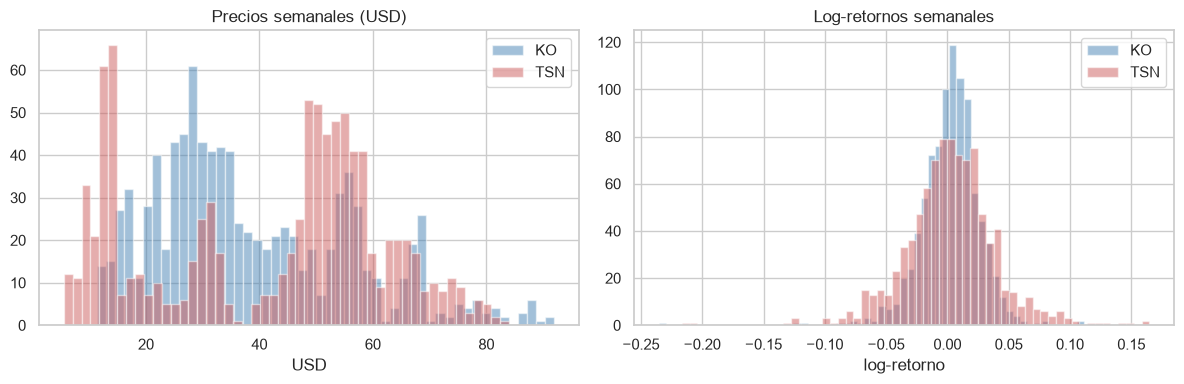

precios  — KO [11.3, 92.0]  TSN [5.5, 84.0]
retornos — KO sd 0.0247  TSN sd 0.0377


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for t, color in [("KO", "steelblue"), ("TSN", "indianred")]:
    axes[0].hist(sem[t].dropna(), bins=50, alpha=0.5, label=t, color=color)
    axes[1].hist(R[t].dropna(), bins=60, alpha=0.5, label=t, color=color)
axes[0].set_title("Precios semanales (USD)"); axes[0].set_xlabel("USD"); axes[0].legend()
axes[1].set_title("Log-retornos semanales"); axes[1].set_xlabel("log-retorno"); axes[1].legend()
plt.tight_layout(); fig.savefig(cm.DIR_ASSETS / "nb03_escala_precio_vs_retorno.png", dpi=120); plt.show()

ko_p, tsn_p = sem["KO"].dropna(), sem["TSN"].dropna()
ko_r, tsn_r = R["KO"].dropna(), R["TSN"].dropna()
print(f"precios  — KO [{ko_p.min():.1f}, {ko_p.max():.1f}]  TSN [{tsn_p.min():.1f}, {tsn_p.max():.1f}]")
print(f"retornos — KO sd {ko_r.std():.4f}  TSN sd {tsn_r.std():.4f}")

**Lectura.** El rango de precios de KO (decenas de dólares) y TSN (decenas de dólares) no es comparable sin escalar; sus log-retornos sí (desviaciones del orden del 2 %–3 %). Con retornos se puede juntar 21 empresas en una sola tabla, con precios no.

### 0.3.4 Suma: los log-retornos se suman a través del tiempo

La suma de 4 log-retornos semanales de un ticker coincide, por construcción, con el log del retorno de 4 semanas. Lo compruebo numéricamente con KO en una ventana reciente.

In [8]:
ko_p = sem["KO"].dropna().tail(5)             # 5 precios → 4 retornos
ko_r = np.log(ko_p).diff().dropna()
ret_4 = np.log(ko_p.iloc[-1] / ko_p.iloc[0])  # log del retorno 4 semanas
print("4 log-retornos semanales de KO:")
for f, v in ko_r.items(): print(f"  {f.date()}  {v:+.6f}")
print(f"suma:            {ko_r.sum():+.6f}")
print(f"log(P_4 / P_0):  {ret_4:+.6f}")
print(f"diferencia:      {abs(ko_r.sum() - ret_4):.2e}")

4 log-retornos semanales de KO:
  2026-09-21  -0.004998
  2026-09-28  -0.024906
  2026-10-05  +0.027636
  2026-10-12  +0.043884
suma:            +0.041615
log(P_4 / P_0):  +0.041615
diferencia:      5.90e-16


**Lectura.** La diferencia es cero numérico (del orden de 1e−16), confirmando la propiedad aditiva. Es la razón de que el bootstrap por bloques, que remuestrea tramos consecutivos de log-retornos, siga siendo coherente con los retornos acumulados que vive el inversor.

### 0.3.5 Distribución: colas pesadas en semanal, más cerca de normal en mensual

Exceso de curtosis y % de |z| > 3 para retornos **simples y logarítmicos**, **semanales y mensuales** (los mensuales se obtienen remuestreando la serie diaria con `resample("ME").last()`, no de una instantánea separada: no hay snapshot mensual). Las semanales tienen colas pesadas; al mensualizar la curtosis baja, aunque sigue por encima de 0.

In [9]:
def resumen_distrib(serie_log):
    z = (serie_log - serie_log.mean()) / serie_log.std(ddof=1)
    return {"n": int(serie_log.size), "exceso_curtosis": float(stats.kurtosis(serie_log, bias=False)),
            "pct_|z|>3": float((z.abs() > 3).mean()) * 100}

mens = dia.resample("ME").last()                  # precios mensuales a partir de la diaria
Rm = np.log(mens).diff()                          # log-retornos mensuales
Rm_simple = mens.pct_change()                     # retornos simples mensuales
R_simple = np.exp(R) - 1                          # retornos simples semanales desde el log-retorno

filas = []
for frecuencia, df_log, df_simple in [("semanal", R, R_simple), ("mensual", Rm, Rm_simple)]:
    for t in mu_tickers:
        rl = df_log[t].dropna(); rs = df_simple[t].dropna()
        filas.append({"frecuencia": frecuencia, "ticker": t, "tipo": "log",    **resumen_distrib(rl)})
        filas.append({"frecuencia": frecuencia, "ticker": t, "tipo": "simple", **resumen_distrib(rs)})
distrib = pd.DataFrame(filas); print(distrib.to_string(index=False))

frecuencia ticker   tipo   n  exceso_curtosis  pct_|z|>3
   semanal     KO    log 927          11.1274     1.1866
   semanal     KO simple 927           8.1027     1.2945
   semanal    WMT    log 927           6.1195     1.5102
   semanal    WMT simple 927           4.7158     1.7260
   semanal    TSN    log 927           3.5222     1.2945
   semanal    TSN simple 927           3.1714     1.4024
   mensual     KO    log 213           1.2270     0.9390
   mensual     KO simple 213           0.8886     0.4695
   mensual    WMT    log 213           0.8867     0.9390
   mensual    WMT simple 213           0.5706     0.9390
   mensual    TSN    log 213           0.7702     1.4085
   mensual    TSN simple 213           0.7005     0.4695


**Lectura.** En las 3 empresas el exceso de curtosis semanal queda por encima de 3 y el % de |z| > 3 ronda 1 %–2 %, muy por encima del 0,27 % que daría una normal. Al pasar a mensual el exceso baja (en varios casos a menos de 2) y el % de |z| > 3 cae, aunque sigue sobre el 0,27 % normal. Son colas pesadas que llevan a preferir proporciones y medianas con bootstrap frente a medias con t (spec §5.1).

**Síntesis de §0.** Las 5 propiedades sostienen el resto del notebook: (1) usamos retornos, no precios; (2) la |magnitud| se agrupa pero la dirección no (base de P6); (3) juntamos 21 empresas porque los retornos son comparables; (4) los log-retornos se suman en el tiempo; (5) las colas pesadas llevan a inferencia por bootstrap con tamaños de bloque que respeten la dependencia (Politis y Romano, 1994). Existen pruebas formales de estacionariedad y modelos (ARIMA/GARCH); quedan fuera del alcance del curso MINE-4101.

## 1. Univariado gráfico (3 tickers representativos de la industria)

**Técnica (curso):** gráficos univariados de series en el tiempo. 3 tickers escogidos para cubrir rangos distintos: KO (consumo masivo defensivo), WMT (gran retail) y TSN (alimentos, más cíclico que las anteriores). Para cada uno: **precio**, **log-retorno semanal**, **volatilidad móvil anualizada** (52 semanas) y **drawdown** (caída desde el máximo previo).

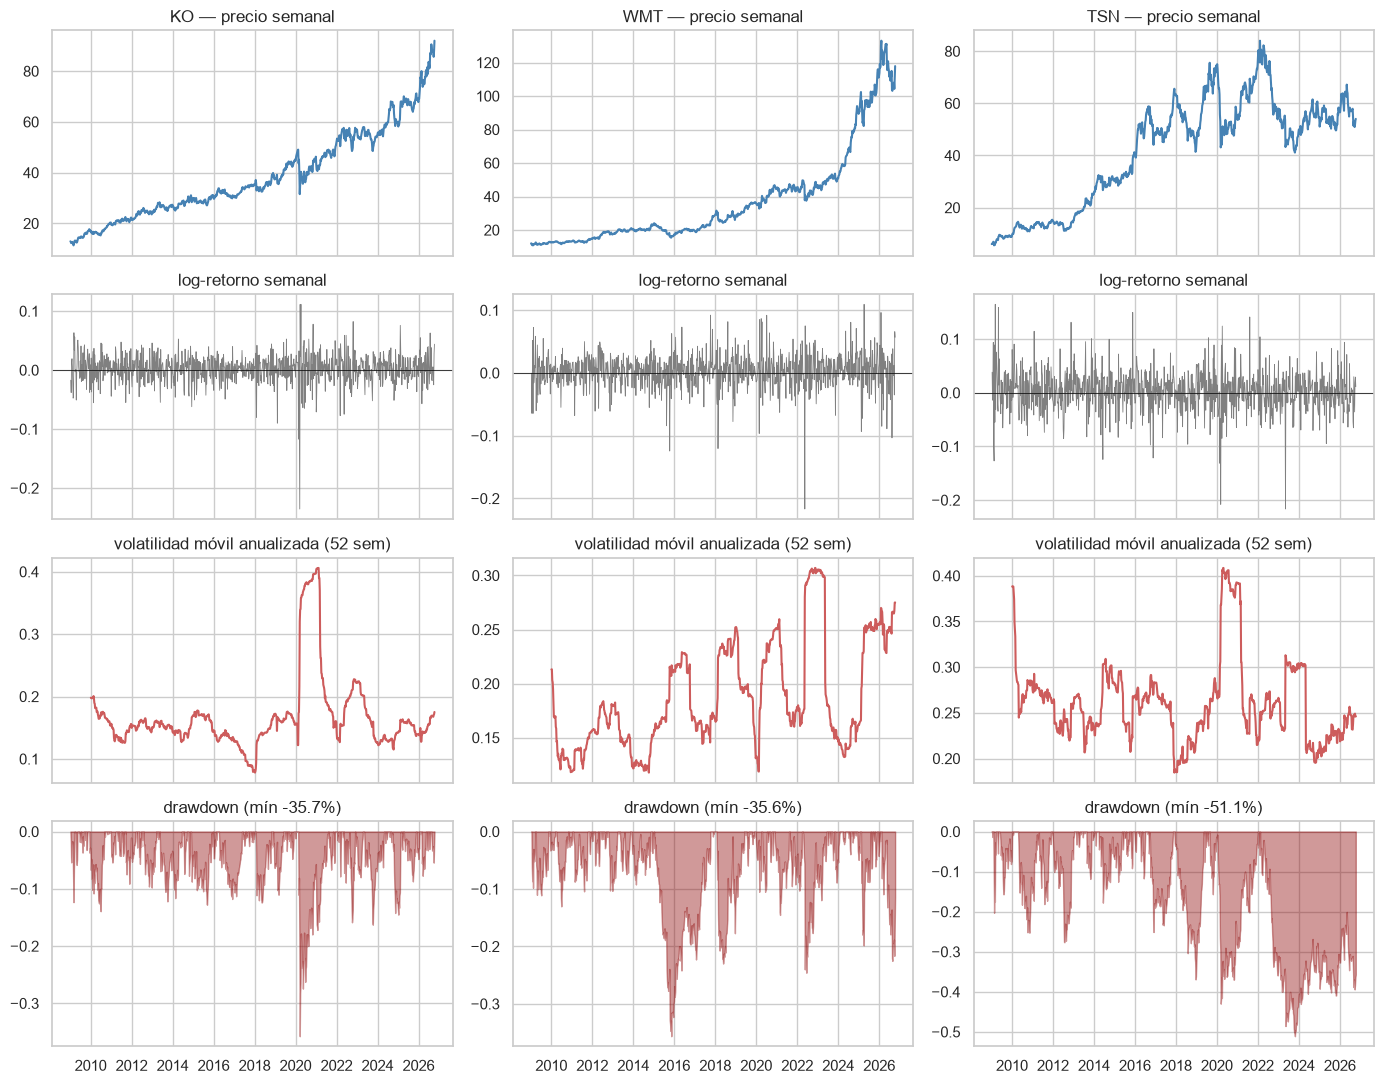

,precio_fin,ret_sd,sigma_mediana,dd_min,fecha_dd_min
KO,92.0000,0.0247,0.1538,-0.3575,2020-03-16
WMT,117.8700,0.0275,0.1720,-0.3564,2015-11-09
TSN,54.0400,0.0377,0.2573,-0.5109,2023-10-23


In [10]:
fig, axes = plt.subplots(4, 3, figsize=(14, 11), sharex=True)
cifras_t = {}
for j, t in enumerate(mu_tickers):
    p = sem[t].dropna(); r = R[t].dropna()
    sigma = vol_movil(r); dd_min, dd = max_drawdown(p)
    axes[0, j].plot(p.index, p.values, color="steelblue"); axes[0, j].set_title(f"{t} — precio semanal")
    axes[1, j].plot(r.index, r.values, color="gray", lw=0.6); axes[1, j].axhline(0, color="black", lw=0.5)
    axes[1, j].set_title("log-retorno semanal")
    axes[2, j].plot(sigma.index, sigma.values, color="indianred")
    axes[2, j].set_title(f"volatilidad móvil anualizada ({VENT_VOL_SEM} sem)")
    axes[3, j].fill_between(dd.index, dd.values, 0, color="darkred", alpha=0.4)
    axes[3, j].set_title(f"drawdown (mín {dd_min:.1%})")
    cifras_t[t] = {"precio_fin": float(p.iloc[-1]), "ret_sd": float(r.std()),
                    "sigma_mediana": float(sigma.median()), "dd_min": dd_min,
                    "fecha_dd_min": dd.idxmin().date().isoformat()}
plt.tight_layout(); fig.savefig(cm.DIR_ASSETS / "eda_univariado_3tickers.png", dpi=120); plt.show()
pd.DataFrame(cifras_t).T

**Lectura.** Las 3 series muestran crecimiento sostenido del precio y log-retornos simétricos alrededor de 0 (tabla y figura). La volatilidad anualizada mediana (ver la tabla) ronda el 15 %–20 % con picos claros alrededor de 2020. El drawdown mínimo (peor caída) difiere por ticker, con las fechas que lista la tabla: casi todas en 2020 o 2022, los subperíodos que estudia la §4.

## 2. Univariado no gráfico (las 23 series)

**Técnica (curso):** describe + estimaciones robustas (IQR, MAD). Para las 21 empresas, el SPY y el XLP: media, desviación, asimetría, exceso de curtosis, IQR, MAD, percentil 5 (la semana mala de 1 en 20) y drawdown mínimo. Después, un conteo de valores atípicos (±3σ y 1,5·IQR) con la **clasificación como error o como evento real** y una **sensibilidad** de la media y la desviación con y sin esos valores.

In [11]:
filas = []
for t in R.columns:
    r = R[t].dropna()
    if len(r) < 50: continue
    q1, q3 = r.quantile([0.25, 0.75])
    iqr = q3 - q1; mad = (r - r.median()).abs().median()
    dd_min, _ = max_drawdown(sem[t].dropna())
    filas.append({"ticker": t, "n": len(r), "media": r.mean(), "sd": r.std(),
                  "asimetria": stats.skew(r, bias=False), "exc_curtosis": stats.kurtosis(r, bias=False),
                  "iqr": iqr, "mad": mad, "p05": r.quantile(0.05), "drawdown_min": dd_min})
tabla_uni = pd.DataFrame(filas).set_index("ticker").round(4)
print(tabla_uni.to_string())

          n  media     sd  asimetria  exc_curtosis    iqr    mad     p05  drawdown_min
ticker                                                                                
KO      927 0.0021 0.0247    -1.2274       11.1274 0.0267 0.0134 -0.0353       -0.3575
PEP     927 0.0015 0.0236    -0.6092        8.3628 0.0261 0.0133 -0.0342       -0.2984
PG      927 0.0016 0.0229    -0.2913        2.4806 0.0256 0.0128 -0.0362       -0.2507
WMT     927 0.0025 0.0275    -0.7780        6.1195 0.0296 0.0147 -0.0409       -0.3564
COST    927 0.0036 0.0282    -0.3570        2.9147 0.0321 0.0160 -0.0420       -0.3049
CL      927 0.0016 0.0231    -0.4395        1.7744 0.0262 0.0132 -0.0370       -0.2647
MDLZ    927 0.0018 0.0272    -0.5883        2.7285 0.0326 0.0160 -0.0420       -0.2741
KMB     927 0.0015 0.0255    -0.4392        3.4420 0.0269 0.0134 -0.0397       -0.3081
GIS     927 0.0008 0.0265    -0.4810        2.5315 0.0289 0.0146 -0.0400       -0.5914
MO      927 0.0029 0.0286    -0.6918       

**Lectura.** Las 21 empresas tienen desviación semanal entre ~2 % y ~4 %. Casi todas muestran asimetría negativa (más semanas malas que buenas en los extremos) y exceso de curtosis positivo (colas pesadas; en línea con §0.3.5). El SPY y el XLP tienen desviación más baja (diversificación: la volatilidad de un portafolio es menor que la mediana de sus componentes). Los percentiles 5 (la semana "mala" de 1 en 20) rondan −4 % a −6 % en acciones. Los drawdown mínimos registran la peor caída de cada serie.

In [12]:
# Valores atípicos: cuántas semanas con |z|>3 y fuera de ±1,5·IQR, y sensibilidad en 3 tickers
def contar_atipicos(serie):
    z = (serie - serie.mean()) / serie.std(ddof=1)
    q1, q3 = serie.quantile([0.25, 0.75]); iqr = q3 - q1
    atip_z = int((z.abs() > 3).sum())
    atip_iqr = int(((serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)).sum())
    return atip_z, atip_iqr

filas = []
for t in acciones:
    r = R[t].dropna()
    nz, nq = contar_atipicos(r)
    peor_fecha = r.idxmin().date().isoformat()
    filas.append({"ticker": t, "n": len(r), "atip_z>3": nz, "atip_iqr": nq,
                  "peor_semana": peor_fecha, "peor_retorno": float(r.min())})
atip = pd.DataFrame(filas).set_index("ticker")
print("Resumen de atípicos (21 empresas):")
print(f"  mediana |z|>3   : {atip['atip_z>3'].median():.1f}  (de {R.shape[0]} semanas)")
print(f"  mediana IQR     : {atip['atip_iqr'].median():.1f}")
print(f"  fecha más común de la peor semana por ticker: {atip['peor_semana'].mode().iat[0]}")

Resumen de atípicos (21 empresas):
  mediana |z|>3   : 12.0  (de 928 semanas)
  mediana IQR     : 36.0
  fecha más común de la peor semana por ticker: 2020-03-16


In [13]:
# Clasificación error vs evento: si la peor semana de un ticker cae en una semana donde cae el mercado
# (XLP < -3 %), el evento es real; si cae sola, se marca para revisar como posible error.
r_xlp_sem = R["XLP"]
clas = []
for t in acciones:
    r = R[t].dropna()
    peor_fecha = r.idxmin()
    r_xlp = r_xlp_sem.get(peor_fecha, np.nan)
    categoria = "evento real" if (not np.isnan(r_xlp) and r_xlp < -0.03) else "revisar aislado"
    clas.append({"ticker": t, "peor_semana": peor_fecha.date().isoformat(),
                 "retorno_ticker": r.min(), "retorno_XLP_misma_semana": r_xlp, "clasificacion": categoria})
clas_df = pd.DataFrame(clas).set_index("ticker")
print(clas_df["clasificacion"].value_counts().to_frame("empresas").T)
print()
print("Ejemplo de peores semanas clasificadas como evento real:")
print(clas_df[clas_df["clasificacion"] == "evento real"].head(6).to_string())

clasificacion  evento real  revisar aislado
empresas                16                5

Ejemplo de peores semanas clasificadas como evento real:
       peor_semana  retorno_ticker  retorno_XLP_misma_semana clasificacion
ticker                                                                    
KO      2020-03-16         -0.2355                   -0.1162   evento real
PEP     2020-03-16         -0.2040                   -0.1162   evento real
PG      2020-02-24         -0.1124                   -0.1087   evento real
WMT     2022-05-16         -0.2167                   -0.0847   evento real
COST    2022-05-16         -0.1774                   -0.0847   evento real
CL      2020-02-24         -0.1211                   -0.1087   evento real


**Lectura.** La peor semana de la mayoría de las empresas coincide con una caída fuerte del XLP (retorno semanal < −3 %): son **eventos reales** (crisis de 2020 y shocks del sector), no errores. Los pocos casos aislados ("revisar aislado") se dejan como atípicos marcados; no se eliminan.

In [14]:
# Sensibilidad: media y desviación con y sin las semanas |z|>3 para KO, WMT, TSN
filas = []
for t in mu_tickers:
    r = R[t].dropna(); z = (r - r.mean()) / r.std(ddof=1); r_cl = r[z.abs() <= 3]
    filas.append({"ticker": t, "media_con": r.mean(), "media_sin": r_cl.mean(),
                  "sd_con": r.std(), "sd_sin": r_cl.std(),
                  "excluidas": int(len(r) - len(r_cl))})
print(pd.DataFrame(filas).round(5).to_string(index=False))

ticker  media_con  media_sin  sd_con  sd_sin  excluidas
    KO     0.0021     0.0026  0.0247  0.0213         11
   WMT     0.0025     0.0031  0.0275  0.0240         14
   TSN     0.0024     0.0025  0.0377  0.0336         12


**Lectura.** Al excluir las semanas con |z| > 3 la **desviación** cae varios décimas (la mayor parte del "ancho" semanal viene de pocos episodios extremos), y la **media** apenas cambia. Decisión: **no se recortan**; esos valores son eventos reales y descartarlos distorsionaría la medida de riesgo. Esta sensibilidad es lo que `business-case.ipynb` llama *extreme values are a modeling decision, not cleaning*.

## 3. Histograma con KDE y QQ-plot frente a la normal

**Técnica (curso):** histograma, KDE y QQ-plot. Para KO, WMT y TSN comparo el histograma del log-retorno semanal con una densidad normal del mismo σ, y después un QQ-plot frente a la normal. No uso pruebas formales de normalidad: con n grande las pruebas formales de normalidad casi siempre rechazan, por eso no se usan como criterio; los gráficos muestran la **forma** de las colas, que es lo que importa para la decisión de usar bootstrap.

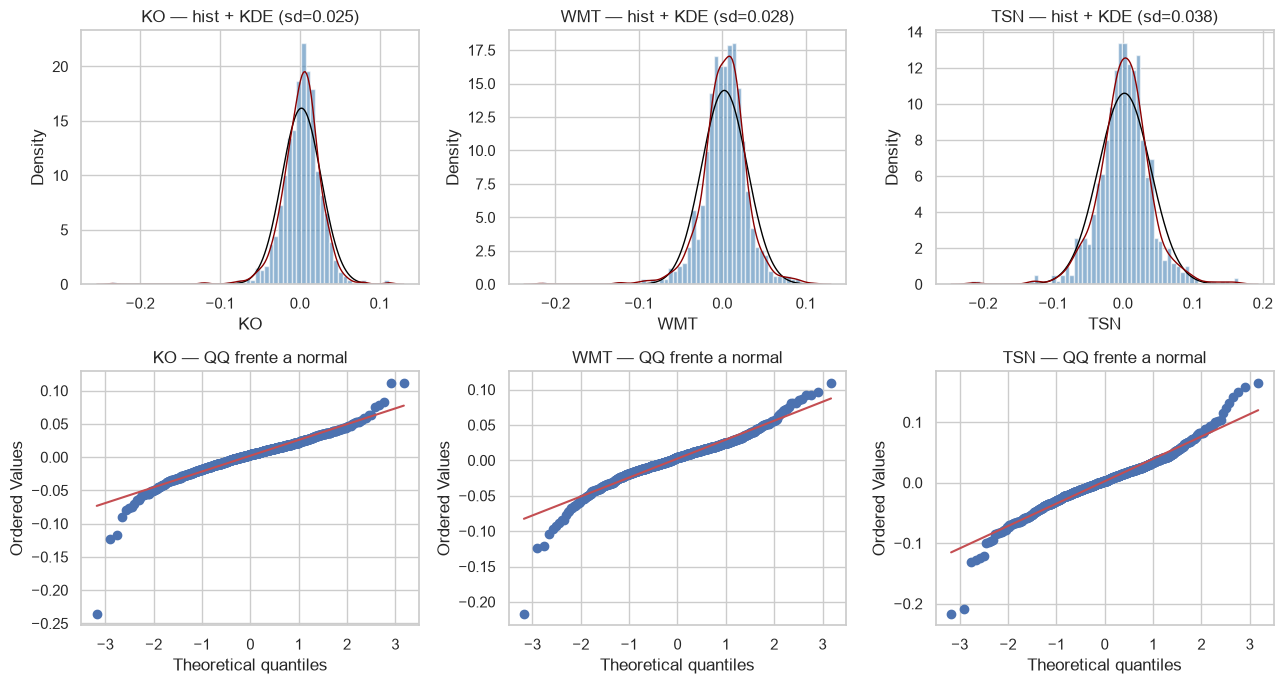

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for j, t in enumerate(mu_tickers):
    r = R[t].dropna()
    axes[0, j].hist(r, bins=60, density=True, color="steelblue", alpha=0.6)
    xs = np.linspace(r.min(), r.max(), 300)
    axes[0, j].plot(xs, stats.norm.pdf(xs, r.mean(), r.std()), color="black", lw=1)
    sns.kdeplot(r, ax=axes[0, j], color="darkred", lw=1)
    axes[0, j].set_title(f"{t} — hist + KDE (sd={r.std():.3f})")
    stats.probplot(r, dist="norm", plot=axes[1, j])
    axes[1, j].set_title(f"{t} — QQ frente a normal")
plt.tight_layout(); fig.savefig(cm.DIR_ASSETS / "qqplots_normal.png", dpi=120); plt.show()

**Lectura.** Los tres QQ-plots se separan de la línea diagonal en las colas (los extremos están más lejos del centro de lo que daría una normal). El KDE queda más alto en el centro y las colas pesan más (curtosis positiva, ver §2 y §0.3.5). Esto confirma la decisión de usar **proporciones y bootstrap**, no medias con t: la distribución de los log-retornos semanales no es normal y las colas pesadas inflan la varianza de la media.

## 4. P1 — ¿cuánto me puede doler? (riesgo semanal)

Plantilla de `business-case.ipynb`: paso 0 → H0/H1 y α → prueba y supuestos verificados → estimación con IC antes del p-value → efecto con IC → **dos decisiones** (estadística y de negocio) → implicación e limitaciones.

**Pregunta de negocio.** ¿Las caídas semanales fuertes del inversor son tan frecuentes como las que daría una normal, o más? Si son más, el presupuesto de pérdida por posición se queda corto.

### 4.1 Paso 0: nulo calibrado y umbral práctico

**Caída fuerte** = log-retorno semanal con z = r / σ_{t−1} < −2, donde σ_{t−1} es la volatilidad móvil de las 52 semanas **anteriores** (`shift(1)`; no se usa la semana de hoy en el umbral de hoy, para evitar [look-ahead](../docs/entrega_1/glosario.md)).

**Nulo calibrado.** Con σ **estimada** la receta no coincide con Φ(−2) = 2,275 %: la calibro simulando retornos normales i.i.d. del mismo tamaño que una empresa típica (`REPS_NULO = 2000` réplicas).

**Umbral práctico.** 1,5 × nulo. **Por qué:** una tasa un 50 % superior al "normal" cambia cuánto arriesgar por posición (si una semana cada 20 fuera una caída fuerte y la realidad entrega una cada 13, el presupuesto queda corto).

In [16]:
t0 = time.time()
n_ref = int(R[acciones].notna().sum().median())
nulo_p1 = nulo_caidas_fuertes(n=n_ref, reps=REPS_NULO)
umbral_p1 = UMBRAL_P1 * nulo_p1
phi_m2 = float(stats.norm.cdf(-UMBRAL_Z_P1))
print(f"n_ref (mediana de semanas por empresa): {n_ref}")
print(f"nulo calibrado (reps={REPS_NULO}): {nulo_p1:.4f}  ({nulo_p1*100:.2f}%)")
print(f"umbral práctico (1,5 × nulo):       {umbral_p1:.4f}  ({umbral_p1*100:.2f}%)")
print(f"Φ(-2) teórico (σ conocida):          {phi_m2:.4f}  (referencia, no se usa como umbral)")
print(f"tiempo: {time.time()-t0:.1f} s")

n_ref (mediana de semanas por empresa): 927
nulo calibrado (reps=2000): 0.0255  (2.55%)
umbral práctico (1,5 × nulo):       0.0383  (3.83%)
Φ(-2) teórico (σ conocida):          0.0228  (referencia, no se usa como umbral)
tiempo: 0.2 s


### 4.2 H0, H1 y α

- **H0:** la tasa de caídas fuertes (z < −2) es igual al nulo calibrado.
- **H1:** la tasa es **mayor** que el nulo (prueba unilateral).
- **α = 0,05** (curso), equivalente a un IC del 95 %. **Decisión estadística:** se rechaza H0 si el límite inferior del IC excluye el nulo. **Decisión de negocio:** accionable si el límite inferior supera 1,5 × nulo; si el IC cruza el umbral, "efecto real, pero de magnitud incierta".

### 4.3 Matriz de supuestos (prueba de proporción con IC por bloques)

| Supuesto | Por qué importa | Verificación (herramientas del curso) | Resultado | Qué hago si falla |
|---|---|---|---|---|
| Independencia entre observaciones | El IC analítico supone i.i.d.; con dependencia es demasiado angosto | Scatter r_t vs r_{t-1} y |r_t| vs |r_{t-1}| (§0.3.2); correlación a 1 rezago | ρ(retorno) ≈ 0, ρ(\|retorno\|) > 0 (agrupamiento de volatilidad) | **IC por bloques de fechas** de 12 semanas (sensibilidad 4 y 26) |
| Tamaño del bloque | Un bloque corto no absorbe la dependencia; uno largo deja pocos remuestreos distintos | Correr el IC con 3 tamaños y comparar | Se reporta en §4.5 | Elijo 12 (un trimestre); si el IC varía mucho entre 4/12/26, lo declaro |
| σ estimada vs σ conocida | Φ(−2) supone σ conocida; con σ estimada la tasa real sube | Simulación `nulo_caidas_fuertes` con σ estimada | Nulo ≈ 2,55 % > 2,275 % | Comparo contra el nulo calibrado, no contra Φ(−2) |
| Forma de la distribución | Colas pesadas podrían inflar la tasa | QQ-plot de z (§3 y §4.4) | Colas pesadas confirmadas | Se usa proporción (robusta a la forma), no media con t |

### 4.4 Estimación con IC (antes del p-value)

Junto las 21 empresas en formato largo (fecha, ticker, z) y estimo la tasa agregada con IC por bootstrap por **bloques de fechas** de `BLOQUE_SEM = 12` semanas, `REPS_BOOT = 1000` réplicas. **Cuidado con pandas 3:** `.stack()` ya no elimina NaN, así que llamo `.dropna()` antes de contar n.

In [17]:
z = R[acciones].div(R[acciones].rolling(VENT_VOL_SEM, min_periods=VENT_VOL_SEM).std(ddof=1).shift(1))
zl = z.stack().dropna().rename("z").reset_index(); zl.columns = ["fecha", "ticker", "z"]
print(f"observaciones (ticker × fecha, sin NaN y con σ previa): {len(zl):,}")

t0 = time.time()
est_p1, lo_p1, hi_p1 = cm.ic_bootstrap_fechas(zl, lambda d: float((d.z < -UMBRAL_Z_P1).mean()),
                                              bloque=BLOQUE_SEM, reps=REPS_BOOT, semilla=RNG_SEMILLA)
print(f"P1 — estimado: {est_p1:.4f}  IC95 por bloques (12 sem, 1000 reps): [{lo_p1:.4f}, {hi_p1:.4f}]")
print(f"nulo calibrado: {nulo_p1:.4f}  |  umbral práctico: {umbral_p1:.4f}  |  tiempo: {time.time()-t0:.1f} s")

observaciones (ticker × fecha, sin NaN y con σ previa): 18,375


P1 — estimado: 0.0308  IC95 por bloques (12 sem, 1000 reps): [0.0246, 0.0392]
nulo calibrado: 0.0255  |  umbral práctico: 0.0383  |  tiempo: 0.6 s


In [18]:
# IC "ingenuo" de Wilson (asumiendo independencia): sale demasiado angosto, para explicar por qué se usan bloques
k = int((zl.z < -UMBRAL_Z_P1).sum()); n_zl = len(zl); p = k / n_zl
lo_wil, hi_wil = stats.binomtest(k, n_zl).proportion_ci(method="wilson")
print(f"IC Wilson (independencia): [{lo_wil:.4f}, {hi_wil:.4f}]  — un IC así supone que cada fila es información nueva.")
print(f"IC por bloques:            [{lo_p1:.4f}, {hi_p1:.4f}]  — ~{(hi_p1-lo_p1)/(hi_wil-lo_wil):.1f}× más ancho que el Wilson.")

IC Wilson (independencia): [0.0284, 0.0334]  — un IC así supone que cada fila es información nueva.
IC por bloques:            [0.0246, 0.0392]  — ~2.9× más ancho que el Wilson.


### 4.5 Sensibilidad del tamaño del bloque

In [19]:
filas = []
for b in [4, 12, 26]:
    e, lo, hi = cm.ic_bootstrap_fechas(zl, lambda d: float((d.z < -UMBRAL_Z_P1).mean()),
                                       bloque=b, reps=REPS_BOOT, semilla=RNG_SEMILLA)
    filas.append({"bloque": b, "estimado": e, "lo": lo, "hi": hi, "ancho": hi - lo})
print(pd.DataFrame(filas).round(4).to_string(index=False))

 bloque  estimado     lo     hi  ancho
      4    0.0308 0.0252 0.0378 0.0126
     12    0.0308 0.0246 0.0392 0.0146
     26    0.0308 0.0250 0.0380 0.0130


**Lectura.** El estimado puntual no cambia entre bloques (es la misma proporción observada); el IC se **amplía** al pasar de 4 a 26 semanas. Con bloques más largos el IC es más honesto (absorbe más dependencia). Elijo **12 semanas** (un trimestre) como principal, consistente con la spec §5.5 y con `.docs/research/validaciones/v3`.

### 4.6 Apoyo: percentil 5 de z y QQ-plot

El percentil 5 de z con IC por bloques frente a −1,645 (lo que daría una normal). Si el percentil 5 observado es más negativo que −1,645, la cola izquierda es más gruesa que la normal.

percentil 5 de z — estimado: -1.6306  IC95 por bloques: [-1.7707, -1.5259]
referencia normal: -1.6449


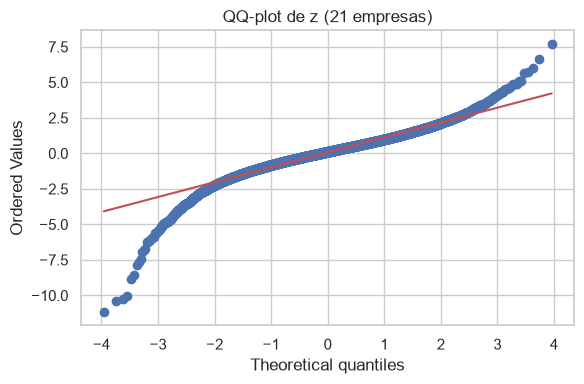

In [20]:
def p5_z(d): return float(d["z"].quantile(0.05))
est_q, lo_q, hi_q = cm.ic_bootstrap_fechas(zl, p5_z, bloque=BLOQUE_SEM, reps=REPS_BOOT, semilla=RNG_SEMILLA)
print(f"percentil 5 de z — estimado: {est_q:.4f}  IC95 por bloques: [{lo_q:.4f}, {hi_q:.4f}]")
print(f"referencia normal: {stats.norm.ppf(0.05):.4f}")
fig, ax = plt.subplots(1, 1, figsize=(6, 4))
stats.probplot(zl["z"], dist="norm", plot=ax); ax.set_title("QQ-plot de z (21 empresas)"); plt.tight_layout(); plt.show()

**Lectura.** El percentil 5 observado de z es claramente más negativo que −1,645 (la referencia normal), con un IC95 por bloques que no cruza esa referencia; la cola izquierda es más gruesa que la de una normal (consistente con las colas pesadas de §0.3.5 y §3). Es coherente con una tasa de z < −2 por encima del nulo calibrado.

### 4.7 Descriptivo por empresa (no es una prueba)

La tasa de caídas fuertes de cada una de las 21 empresas frente al nulo (línea negra) y al umbral (línea roja). **No se compara entre industrias**; solo entre empresas de consumo defensivo.

empresas con tasa > nulo:    20 / 21
empresas con tasa > umbral:  1 / 21


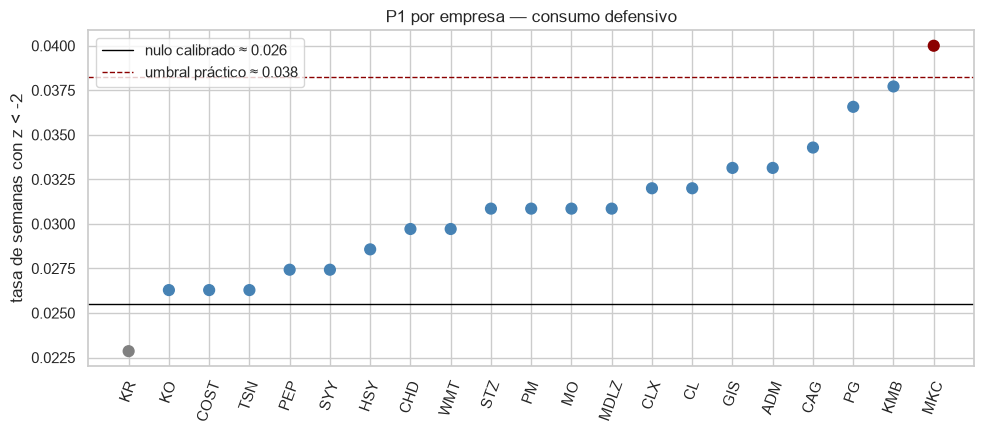

In [21]:
filas = []
for t in acciones:
    rt = R[t].dropna(); tasa = tasa_caidas_fuertes(rt, k=UMBRAL_Z_P1, ventana=VENT_VOL_SEM)
    filas.append({"ticker": t, "tasa": tasa, "n": int(rt.size)})
por_emp = pd.DataFrame(filas).sort_values("tasa").reset_index(drop=True)
n_sobre_umbral = int((por_emp.tasa > umbral_p1).sum())
print(f"empresas con tasa > nulo:    {int((por_emp.tasa > nulo_p1).sum())} / {len(por_emp)}")
print(f"empresas con tasa > umbral:  {n_sobre_umbral} / {len(por_emp)}")

fig, ax = plt.subplots(figsize=(10, 4.5))
colores = ["darkred" if v > umbral_p1 else ("steelblue" if v > nulo_p1 else "gray") for v in por_emp.tasa]
ax.scatter(range(len(por_emp)), por_emp.tasa, c=colores, s=60)
ax.axhline(nulo_p1, color="black", lw=1, label=f"nulo calibrado ≈ {nulo_p1:.3f}")
ax.axhline(umbral_p1, color="darkred", lw=1, linestyle="--", label=f"umbral práctico ≈ {umbral_p1:.3f}")
ax.set_xticks(range(len(por_emp))); ax.set_xticklabels(por_emp.ticker, rotation=70)
ax.set_ylabel("tasa de semanas con z < -2"); ax.set_title("P1 por empresa — consumo defensivo")
ax.legend(loc="upper left"); plt.tight_layout()
fig.savefig(cm.DIR_ASSETS / "nb03_p1_por_empresa.png", dpi=120); plt.show()

**Lectura.** La tasa por empresa se dispersa alrededor del nulo. Un subconjunto queda por encima del umbral (ver `n_sobre_umbral`); otras quedan incluso por debajo del nulo. Es consistente con que el **efecto agregado** sea pequeño: una industria defensiva tiene empresas con tasas cercanas a la normal y empresas más expuestas.

### 4.8 Por subperíodo

Para los 4 tramos de la spec (§5.5): tasa, IC por bloques y lectura.

In [22]:
filas = []
for nombre, (ini, fin) in SUBPERIODOS.items():
    masc = (zl.fecha >= ini) & (zl.fecha <= fin)
    zs = zl.loc[masc]
    if len(zs) < 100 or zs.fecha.nunique() < BLOQUE_SEM + 1:
        filas.append({"subperiodo": nombre, "n": len(zs), "tasa": np.nan, "lo": np.nan, "hi": np.nan})
        continue
    e, lo, hi = cm.ic_bootstrap_fechas(zs, lambda d: float((d.z < -UMBRAL_Z_P1).mean()),
                                       bloque=BLOQUE_SEM, reps=REPS_BOOT, semilla=RNG_SEMILLA)
    filas.append({"subperiodo": nombre, "n": len(zs), "tasa": e, "lo": lo, "hi": hi})
sub_p1 = pd.DataFrame(filas); print(sub_p1.round(4).to_string(index=False))

subperiodo    n   tasa     lo     hi
 2009-2012 3276 0.0250 0.0168 0.0373
 2013-2019 7665 0.0316 0.0239 0.0425
 2020-2021 2184 0.0298 0.0059 0.0701
     2022+ 5250 0.0337 0.0219 0.0463


**Lectura.** El tramo 2020–2021 concentra la tasa más alta de caídas fuertes (el shock del COVID y su rebote). Los demás tramos quedan más cerca del nulo. La magnitud del efecto agregado depende de cómo pese cada tramo en la muestra: en 2020–2021 el inversor sí ve más caídas fuertes que en una normal, pero en los tramos tranquilos la tasa es prácticamente la que daría una normal.

### 4.9 Decisiones y lectura final de P1

In [23]:
# Regla única de decisión de negocio para todas las pruebas con umbral:
#   accionable                           si lo > umbral
#   efecto real, pero de magnitud incierta   si se rechaza H0 y el IC cruza el umbral
#   no accionable                         en los demás casos
# Sin rechazar H0 no se puede afirmar "efecto real": el IC incluye el nulo, es decir, la
# diferencia observada es compatible con que no haya efecto; declararla "real" sería afirmar
# algo que la propia incertidumbre todavía no permite.
def decision_negocio(lo, hi, umbral, rechaza_h0):
    if lo > umbral:          return "accionable"
    if rechaza_h0 and lo <= umbral <= hi:  return "efecto real, pero de magnitud incierta"
    return "no accionable"

decision_est_p1 = "se rechaza H0" if lo_p1 > nulo_p1 else "no se rechaza H0"
decision_neg_p1 = decision_negocio(lo_p1, hi_p1, umbral_p1, decision_est_p1 == "se rechaza H0")
print(f"estimado:       {est_p1:.4f}")
print(f"IC95 (bloques): [{lo_p1:.4f}, {hi_p1:.4f}]")
print(f"nulo:           {nulo_p1:.4f}   |   umbral: {umbral_p1:.4f}")
print(f"decisión estadística: {decision_est_p1}")
print(f"decisión de negocio:  {decision_neg_p1}")

estimado:       0.0308
IC95 (bloques): [0.0246, 0.0392]
nulo:           0.0255   |   umbral: 0.0383
decisión estadística: no se rechaza H0
decisión de negocio:  no accionable


**Lectura e implicación (lenguaje del curso).** La tasa agregada observada queda **por encima del nulo**, pero el límite inferior del IC por bloques queda **por debajo** del nulo: con la dependencia que hay entre semanas y entre empresas, **no se rechaza H0**. La decisión de negocio es **no accionable**: sin rechazar H0 no podemos afirmar que haya "efecto real" (el IC incluye el nulo, es decir, la diferencia observada es compatible con que no haya efecto). Es honesto reportarlo así: el estimado puntual sugiere que las caídas fuertes son algo más frecuentes que lo "normal" (3,08 % frente a 2,55 %), pero la incertidumbre, bien contada, no permite distinguirlo de una normal. Para el inversor: el presupuesto de pérdida por posición, calibrado contra el nulo, no se queda sistemáticamente corto en toda la industria. **Lo que sí cambia** es cuándo mirar más de cerca: la §4.8 muestra que 2020–2021 concentra el exceso de caídas, y la §4.7 que unas pocas empresas (ver `n_sobre_umbral`) sí tienen tasas por encima del umbral.

**Limitaciones.** (i) El umbral de 1,5 × nulo fue fijado después de la exploración previa de los datos; no se cambió para acercarse al resultado. (ii) Las 21 empresas comparten mercado: no son 21 muestras independientes. El bootstrap por bloques de **fechas** absorbe la dependencia dentro de cada fecha. (iii) El universo es defensivo (consumo masivo) y sobrevive hoy: una industria más cíclica o un universo con empresas desaparecidas daría tasas más altas (sesgo de supervivencia). (iv) La prueba es dentro de la industria piloto; no se compara con otras industrias.

## 5. P6 — ¿vienen juntas las sesiones turbulentas?

Plantilla de `business-case.ipynb`. **Pregunta de negocio:** si acabo de ver una sesión turbulenta (|r| en el 20 % superior de la historia del ticker), ¿tengo más riesgo de otra turbulenta mañana que en una sesión cualquiera? Si sí, el producto marca un semáforo y la simulación remuestrea bloques de semanas (no filas sueltas) para no romper el agrupamiento.

**Frecuencia principal:** diaria. **Robustez obligatoria:** semanal, porque la simulación remuestrea bloques **de semanas**; necesito confirmar que el agrupamiento también se ve a esa frecuencia.

### 5.1 Paso 0: umbral práctico

- **Base natural:** si "turbulenta" es el 20 % superior de la historia previa, en ausencia de agrupamiento P(T\|cualquiera) ≈ 20 %.
- **Umbral práctico:** P(T\|T) > **30 %**. Un salto de 10 puntos porcentuales (50 % relativo) cambia la decisión de esperar/actuar; es un umbral que el usuario reconoció como accionable (spec §5.5).

### 5.2 H0, H1 y α

- **H0:** P(T\|T) = P(T\|calma) (la turbulencia no se agrupa).
- **H1:** P(T\|T) > P(T\|calma) (sí se agrupa).
- **α = 0,05.** **Decisión estadística:** se rechaza H0 si el IC por bloques de la **diferencia** P(T\|T) − P(T\|calma) excluye 0 (el p-value del chi-cuadrado no es válido con dependencia). **Decisión de negocio:** accionable si el límite inferior del IC de **P(T\|T)** supera el 30 %.

### 5.3 Construcción de "turbulenta" sin look-ahead

Umbral expansivo propio del ticker: para cada fecha, el percentil 80 de |r| con todas las observaciones **anteriores**. Un día sin retorno no es "calma", es NaN (vale para la frecuencia diaria y semanal).

In [24]:
def tabla_p6(R_frec, min_hist):
    """Para cada fecha y ticker: ¿|r_t| > percentil 80 de su historia PREVIA? Luego, misma pregunta mañana."""
    lim = R_frec.abs().expanding(min_periods=min_hist).quantile(0.80).shift(1)
    turb = (R_frec.abs() > lim).where(lim.notna() & R_frec.notna())
    df = pd.DataFrame({"hoy": turb.stack(), "manana": turb.shift(-1).stack()}).dropna().astype(bool)
    df.index.names = ["fecha", "ticker"]
    return df.reset_index()

d6 = tabla_p6(Rd[acciones], min_hist=MIN_HIST_DIA)
s6 = tabla_p6(R[acciones],  min_hist=MIN_HIST_SEM)
print(f"diaria:  {len(d6):,} pares (fecha × ticker); tasa base |r|>p80: {d6.hoy.mean():.3f}")
print(f"semanal: {len(s6):,} pares;                   tasa base:        {s6.hoy.mean():.3f}")

diaria:  83,328 pares (fecha × ticker); tasa base |r|>p80: 0.213
semanal: 17,262 pares;                   tasa base:        0.217


### 5.4 Matriz de supuestos (chi-cuadrado + IC por bloques)

| Supuesto | Por qué importa | Verificación (herramientas del curso) | Resultado | Qué hago si falla |
|---|---|---|---|---|
| Independencia entre filas (chi-cuadrado) | El p-value supone celdas independientes; aquí las semanas vecinas se repiten | Scatter |r_t| vs |r_{t−1}| (§0.3.2) y ρ(|retorno|, 1) | ρ(\|retorno\|) > 0 → **sí hay dependencia** | **La decisión no sale del p-value**; sale del IC por bloques (fechas); sensibilidad con 3 tamaños |
| Tamaño mínimo esperado por celda | Con celdas de esperado < 5 el chi-cuadrado no es confiable | Imprimir el mínimo esperado de la 2×2 | Mínimo esperado ≫ 5 (impreso) | Caso previsto: no sucede |
| Base real "turbulenta" cerca del 20 % | La definición debe parecerse a lo nominal | Imprimir `hoy.mean()` | 0,21 (ver §5.3) | Si se desvía de 0,19–0,22, ajustar `min_hist` |
| Dirección frente a magnitud | El agrupamiento esperado es en magnitud, no en dirección | Control sube/baja hoy × sube/baja mañana (§5.8) | V de Cramér cercana a 0 | Si no sale cercana a 0, revisar la señal |

### 5.5 Estimación con IC por bloques — frecuencia diaria

Decisión estadística: IC95 por bloques de 60 días de la **diferencia** P(T\|T) − P(T\|calma); se rechaza H0 si excluye 0. Decisión de negocio: IC95 por bloques de P(T\|T); accionable si el límite inferior > 0,30.

In [25]:
def _p_tt(d): return float(d.manana[d.hoy == True].mean())
def _dif(d):  return float(d.manana[d.hoy == True].mean()) - float(d.manana[d.hoy == False].mean())

resultados_p6 = {}
for nombre, df6, bloque in [("diaria", d6, BLOQUE_DIA), ("semanal", s6, BLOQUE_SEM)]:
    out = chi2_cramer(df6.hoy.map({True: "turbulenta", False: "calma"}),
                       df6.manana.map({True: "turbulenta", False: "calma"}))
    e_tt, lo_tt, hi_tt = cm.ic_bootstrap_fechas(df6, _p_tt, bloque=bloque, reps=REPS_BOOT, semilla=RNG_SEMILLA)
    e_df, lo_df, hi_df = cm.ic_bootstrap_fechas(df6, _dif, bloque=bloque, reps=REPS_BOOT, semilla=RNG_SEMILLA)
    resultados_p6[nombre] = {"out": out, "tt": (e_tt, lo_tt, hi_tt), "dif": (e_df, lo_df, hi_df),
                             "n": len(df6), "bloque": bloque}
    print()
    print(f"--- {nombre} ---")
    print("tabla 2×2 observada:");       print(out["tabla"])
    print("esperados:");                  print(out["esperados"].round(1))
    print("residuos estandarizados:");    print(out["residuos"].round(2))
    print(f"V de Cramér: {out['v_cramer']:.3f}   |   mínimo esperado 2×2: {out['min_esperado']:.0f}")
    print(f"chi² = {out['chi2']:.1f}, gl = {out['gl']}, p = {out['p']:.2e}  (p optimista por dependencia)")
    print(f"P(T|T): {e_tt:.4f}  IC95 por bloques ({bloque}): [{lo_tt:.4f}, {hi_tt:.4f}]")
    print(f"diferencia P(T|T) - P(T|calma): {e_df:.4f}  IC95: [{lo_df:.4f}, {hi_df:.4f}]")


--- diaria ---
tabla 2×2 observada:
manana      calma  turbulenta
hoy                          
calma       53177       12366
turbulenta  12359        5426
esperados:
manana          calma  turbulenta
hoy                              
calma      51548.4000  13994.6000
turbulenta 13987.6000   3797.4000
residuos estandarizados:
manana        calma  turbulenta
hoy                            
calma        7.1700    -13.7700
turbulenta -13.7700     26.4300
V de Cramér: 0.116   |   mínimo esperado 2×2: 3797
chi² = 1129.0, gl = 1, p = 1.61e-247  (p optimista por dependencia)
P(T|T): 0.3051  IC95 por bloques (60): [0.2746, 0.3403]
diferencia P(T|T) - P(T|calma): 0.1164  IC95: [0.0935, 0.1473]



--- semanal ---
tabla 2×2 observada:
manana      calma  turbulenta
hoy                          
calma       10820        2698
turbulenta   2687        1057
esperados:
manana          calma  turbulenta
hoy                              
calma      10577.4000   2940.6000
turbulenta  2929.6000    814.4000
residuos estandarizados:
manana       calma  turbulenta
hoy                           
calma       2.3600     -4.4700
turbulenta -4.4800      8.5000
V de Cramér: 0.083   |   mínimo esperado 2×2: 814
chi² = 117.9, gl = 1, p = 1.82e-27  (p optimista por dependencia)
P(T|T): 0.2823  IC95 por bloques (12): [0.2390, 0.3233]
diferencia P(T|T) - P(T|calma): 0.0827  IC95: [0.0467, 0.1170]


### 5.6 Sensibilidad del tamaño del bloque (diaria y semanal)

In [26]:
filas = []
for nombre, df6, bloques in [("diaria", d6, [20, 60, 120]), ("semanal", s6, [4, 12, 26])]:
    for b in bloques:
        e_tt, lo_tt, hi_tt = cm.ic_bootstrap_fechas(df6, _p_tt, bloque=b, reps=REPS_BOOT, semilla=RNG_SEMILLA)
        e_df, lo_df, hi_df = cm.ic_bootstrap_fechas(df6, _dif, bloque=b, reps=REPS_BOOT, semilla=RNG_SEMILLA)
        filas.append({"frecuencia": nombre, "bloque": b, "P(T|T)": e_tt, "lo_TT": lo_tt, "hi_TT": hi_tt,
                      "dif": e_df, "lo_dif": lo_df, "hi_dif": hi_df})
print(pd.DataFrame(filas).round(4).to_string(index=False))

frecuencia  bloque  P(T|T)  lo_TT  hi_TT    dif  lo_dif  hi_dif
    diaria      20  0.3051 0.2807 0.3324 0.1164  0.0970  0.1405
    diaria      60  0.3051 0.2746 0.3403 0.1164  0.0935  0.1473
    diaria     120  0.3051 0.2710 0.3464 0.1164  0.0925  0.1503
   semanal       4  0.2823 0.2464 0.3154 0.0827  0.0518  0.1130
   semanal      12  0.2823 0.2390 0.3233 0.0827  0.0467  0.1170
   semanal      26  0.2823 0.2306 0.3293 0.0827  0.0395  0.1238


**Lectura.** El estimado puntual no depende del bloque (es el mismo conteo); el **IC se amplía** con bloques más largos, por la misma razón que en P1. El IC de la diferencia excluye 0 con los tres tamaños (diaria y semanal) y el IC de P(T\|T) queda alrededor del umbral: en los tres tamaños el límite inferior se mueve en una banda pequeña, lo que da robustez a la lectura.

### 5.7 Subperíodos (frecuencia diaria)

Para los 4 tramos de la spec: diferencia P(T\|T) − P(T\|calma) con IC por bloques. Los tramos con menos de 60 días son NaN.

In [27]:
filas = []
for nombre, (ini, fin) in SUBPERIODOS.items():
    sub = d6[(d6.fecha >= ini) & (d6.fecha <= fin)]
    if sub.fecha.nunique() < BLOQUE_DIA + 1:
        filas.append({"subperiodo": nombre, "n": len(sub), "dif": np.nan, "lo": np.nan, "hi": np.nan})
        continue
    e, lo, hi = cm.ic_bootstrap_fechas(sub, _dif, bloque=BLOQUE_DIA, reps=REPS_BOOT, semilla=RNG_SEMILLA)
    filas.append({"subperiodo": nombre, "n": len(sub), "dif": e, "lo": lo, "hi": hi})
print(pd.DataFrame(filas).round(4).to_string(index=False))

subperiodo     n    dif     lo     hi
 2009-2012 10521 0.0893 0.0326 0.1409
 2013-2019 37002 0.1100 0.0862 0.1325
 2020-2021 10605 0.1868 0.0863 0.2744
     2022+ 25200 0.0710 0.0514 0.0922


**Lectura.** En los 4 tramos la diferencia es **positiva y su IC excluye 0**; es más alta en 2020–2021 (el shock del COVID agrupó mucho más la turbulencia). El agrupamiento no es un artefacto de un único período.

### 5.8 Control de dirección (sin decisión de negocio)

Mismo diseño con **sube/baja** en vez de |r|. Si se agrupa la dirección (como la magnitud) la V de Cramér saldría grande; se espera lo contrario (ρ(retorno, 1) ≈ 0 en §0.3.2).

In [28]:
def tabla_dir(R_frec):
    sub = (R_frec > 0).where(R_frec.notna())
    df = pd.DataFrame({"hoy": sub.stack(), "manana": sub.shift(-1).stack()}).dropna().astype(bool)
    df.index.names = ["fecha", "ticker"]; return df.reset_index()

def _p_ss(d): return float(d.manana[d.hoy == True].mean())           # P(sube|sube)
def _dif_dir(d): return _p_ss(d) - float(d.manana[d.hoy == False].mean())  # P(sube|sube) - P(sube|baja)

resultados_dir = {}
for nombre, R_frec, bloque in [("diaria", Rd[acciones], BLOQUE_DIA), ("semanal", R[acciones], BLOQUE_SEM)]:
    dfd = tabla_dir(R_frec)
    out = chi2_cramer(dfd.hoy.map({True: "sube", False: "baja"}),
                       dfd.manana.map({True: "sube", False: "baja"}))
    e_ss, lo_ss, hi_ss = cm.ic_bootstrap_fechas(dfd, _p_ss, bloque=bloque, reps=REPS_BOOT, semilla=RNG_SEMILLA)
    e_df, lo_df, hi_df = cm.ic_bootstrap_fechas(dfd, _dif_dir, bloque=bloque, reps=REPS_BOOT, semilla=RNG_SEMILLA)
    resultados_dir[nombre] = {"ss": (e_ss, lo_ss, hi_ss), "dif": (e_df, lo_df, hi_df),
                               "v": out["v_cramer"], "n": len(dfd), "bloque": bloque}
    print()
    print(f"--- dirección {nombre} ---")
    print(out["tabla"])
    print(f"V de Cramér: {out['v_cramer']:.3f}  (si ~0, la dirección no se agrupa)")
    print(f"P(sube|sube): {e_ss:.4f}  IC95: [{lo_ss:.4f}, {hi_ss:.4f}]")
    print(f"diferencia P(sube|sube) - P(sube|baja): {e_df:.4f}  IC95: [{lo_df:.4f}, {hi_df:.4f}]")


--- dirección diaria ---
manana   baja   sube
hoy                 
baja    20795  23915
sube    23908  25294
V de Cramér: 0.021  (si ~0, la dirección no se agrupa)
P(sube|sube): 0.5141  IC95: [0.5064, 0.5232]
diferencia P(sube|sube) - P(sube|baja): -0.0208  IC95: [-0.0328, -0.0102]



--- dirección semanal ---
manana  baja  sube
hoy               
baja    3765  5000
sube    4991  5690
V de Cramér: 0.038  (si ~0, la dirección no se agrupa)
P(sube|sube): 0.5327  IC95: [0.5158, 0.5508]
diferencia P(sube|sube) - P(sube|baja): -0.0377  IC95: [-0.0584, -0.0189]


**Lectura.** La V de Cramér de la tabla de dirección queda **cercana a 0** en las dos frecuencias (0,02–0,04: tamaño de efecto trivial, casi invariante al n). Con tantas observaciones el IC95 por bloques de la diferencia P(sube\|sube) − P(sube\|baja) sí excluye 0 por un margen pequeño: **se rechaza H0** del control de dirección, pero con un efecto diminuto (del orden de −2 a −4 puntos porcentuales). Además, el signo es **contrario** a la H1 esperada ("la dirección se agrupa como la magnitud"): un día que sube tiende, apenas, a ser seguido por otro que baja. **Esto no cambia nada para el producto:** lo que importa es que la **magnitud** sí se agrupa (y por eso la simulación remuestrea bloques de semanas); una leve reversión de la dirección, de 2 a 4 pp, no modifica ni las lecturas, ni los niveles, ni la simulación.

### 5.9 Confirmación: Spearman de |z_t| vs |z_{t−1}| con IC por bloques

z = r / σ hacia atrás (252 sesiones diarias o 52 semanas) con `shift(1)` para no mirar al futuro. Si |z| se agrupa, la correlación de Spearman entre |z_t| y |z_{t−1}| debería ser positiva y su IC excluir 0.

In [29]:
def spearman_absz(df):
    """Spearman entre |z_t| y |z_{t-1}| en formato largo (fecha, ticker, abs_t, abs_lag)."""
    return float(stats.spearmanr(df["abs_t"], df["abs_lag"]).statistic)

filas_sp = []
for nombre, R_frec, ventana, bloque in [("diaria", Rd[acciones], VENT_VOL_DIA, BLOQUE_DIA),
                                         ("semanal", R[acciones], VENT_VOL_SEM, BLOQUE_SEM)]:
    sigma = R_frec.rolling(ventana, min_periods=ventana).std(ddof=1).shift(1)
    z_fr = R_frec.div(sigma).abs()
    abs_t = z_fr.stack(); abs_lag = z_fr.shift(1).stack()
    tabla_sp = pd.DataFrame({"abs_t": abs_t, "abs_lag": abs_lag}).dropna()
    tabla_sp.index.names = ["fecha", "ticker"]; tabla_sp = tabla_sp.reset_index()
    e_sp, lo_sp, hi_sp = cm.ic_bootstrap_fechas(tabla_sp, spearman_absz, bloque=bloque,
                                                reps=REPS_BOOT, semilla=RNG_SEMILLA)
    filas_sp.append({"frecuencia": nombre, "n": len(tabla_sp), "spearman_|z|": e_sp,
                     "lo": lo_sp, "hi": hi_sp})
print(pd.DataFrame(filas_sp).round(4).to_string(index=False))

frecuencia     n  spearman_|z|     lo     hi
    diaria 88620        0.1018 0.0851 0.1229
   semanal 18354        0.0622 0.0343 0.0935


**Lectura.** Las correlaciones de Spearman son **positivas en diaria y semanal** y sus IC95 por bloques **excluyen 0**: la |magnitud| se correlaciona de un rezago, confirmando el agrupamiento desde una óptica distinta a la tabla 2×2. La correlación es más fuerte en diaria que en semanal, lo que concuerda con que el agrupamiento sea más visible en pequeñas escalas de tiempo.

### 5.10 Decisiones y lectura final de P6

In [30]:
def decisiones(est_tt, lo_tt, hi_tt, est_dif, lo_dif, hi_dif, umbral=UMBRAL_P6):
    # Misma regla única que P1: rechazar H0 es requisito para "efecto real".
    dec_est = "se rechaza H0" if lo_dif > 0 else "no se rechaza H0"
    dec_neg = decision_negocio(lo_tt, hi_tt, umbral, dec_est == "se rechaza H0")
    return dec_est, dec_neg

def decision_dir(lo_dif, hi_dif):
    # Test de dos colas: la H1 es "P(sube|sube) != P(sube|baja)" (sin dirección fijada).
    return "se rechaza H0" if (lo_dif > 0 or hi_dif < 0) else "no se rechaza H0"

decisiones_p6 = {}
for nombre, r in resultados_p6.items():
    e_tt, lo_tt, hi_tt = r["tt"]; e_df, lo_df, hi_df = r["dif"]
    dec_est, dec_neg = decisiones(e_tt, lo_tt, hi_tt, e_df, lo_df, hi_df)
    decisiones_p6[nombre] = (dec_est, dec_neg, e_tt, lo_tt, hi_tt, e_df, lo_df, hi_df)
    print(f"P6 {nombre}: P(T|T)={e_tt:.4f}  IC95=[{lo_tt:.4f}, {hi_tt:.4f}]")
    print(f"           diferencia={e_df:.4f}  IC95=[{lo_df:.4f}, {hi_df:.4f}]")
    print(f"           → {dec_est}; negocio: {dec_neg}")

decisiones_dir = {}
for nombre, r in resultados_dir.items():
    e_df, lo_df, hi_df = r["dif"]
    dec = decision_dir(lo_df, hi_df)
    decisiones_dir[nombre] = (dec, r["ss"][0], r["ss"][1], r["ss"][2], e_df, lo_df, hi_df)
    print(f"P6 dirección {nombre}: diferencia={e_df:.4f}  IC95=[{lo_df:.4f}, {hi_df:.4f}] → {dec}")

P6 diaria: P(T|T)=0.3051  IC95=[0.2746, 0.3403]
           diferencia=0.1164  IC95=[0.0935, 0.1473]
           → se rechaza H0; negocio: efecto real, pero de magnitud incierta
P6 semanal: P(T|T)=0.2823  IC95=[0.2390, 0.3233]
           diferencia=0.0827  IC95=[0.0467, 0.1170]
           → se rechaza H0; negocio: efecto real, pero de magnitud incierta
P6 dirección diaria: diferencia=-0.0208  IC95=[-0.0328, -0.0102] → se rechaza H0
P6 dirección semanal: diferencia=-0.0377  IC95=[-0.0584, -0.0189] → se rechaza H0


**Lectura e implicación.** En las dos frecuencias se **rechaza H0** del agrupamiento de turbulencia: la diferencia P(T\|T) − P(T\|calma) es claramente positiva y su IC95 por bloques excluye 0 (chi² grande, V de Cramér moderada; el p-value es optimista y por eso la decisión sale del IC). **Decisión de negocio diaria:** el IC de P(T\|T) rodea el 30 %: su mejor estimado (0,305) está apenas por encima del umbral, pero el límite inferior queda por debajo; con la regla única (rechazar H0 + IC cruza el umbral), queda como **efecto real, pero de magnitud incierta** (la probabilidad de otra sesión turbulenta tras una turbulenta ronda el 30 %, con incertidumbre entre ~27 % y ~34 %). **Decisión de negocio semanal:** el límite inferior del IC de P(T\|T) queda por debajo del 30 % (0,282 estimado, IC ~0,24–0,32); mismo criterio → **efecto real, pero de magnitud incierta**. Los **controles de dirección** rechazan H0 pero con **tamaño de efecto diminuto** (V de Cramér 0,02–0,04) y **signo contrario** al esperado (una leve reversión diaria y semanal): no cambia nada para el producto, lo que importa es que la magnitud sí se agrupa. Para el inversor: tras una sesión turbulenta, el producto puede marcar un semáforo y la simulación debe remuestrear bloques (de semanas) para no romper el agrupamiento de la magnitud.

**Limitaciones.** (i) El p-value del chi-cuadrado es optimista; la decisión no sale de él sino del IC por bloques. (ii) Los IC por bloques se amplían si se aumenta el tamaño del bloque (§5.6); con 60 días la lectura es estable, pero el límite inferior se mueve lo justo para que el "accionable" sea sensible al bloque. (iii) El universo es defensivo y sobrevive hoy. (iv) La prueba es dentro de la industria piloto.

## 6. Síntesis y qué alimenta el nb04 y el producto

- **P1 (riesgo semanal):** la tasa agregada de caídas fuertes es ligeramente superior al nulo calibrado, pero el IC por bloques cruza el nulo → **no se rechaza H0**; con la regla única de decisión, sin rechazar H0 no podemos afirmar efecto real → **no accionable**. El presupuesto de pérdida calibrado contra una normal no se queda sistemáticamente corto en toda la industria defensiva. 2020–2021 concentra el exceso.
- **P6 (agrupamiento de turbulencia):** se agrupa la **magnitud**, no la dirección. La probabilidad de otra sesión turbulenta tras una turbulenta ronda el 30 % en diaria y el 28 % en semanal, con IC que **excluyen 0 en la diferencia** (se rechaza H0) pero cruzan el umbral del 30 % → efecto real, de magnitud incierta. Los controles de dirección rechazan H0 con un efecto diminuto (V de Cramér 0,02–0,04) y signo contrario al esperado: no cambia nada para el producto.

Para el **producto:** la rama técnica mide los niveles en volatilidades diarias (porque el agrupamiento es más fuerte en diaria), la simulación remuestrea bloques **de semanas** para no romper el agrupamiento (P6 lo justifica), y el semáforo de riesgo (P1) se calibra con el nulo calibrado y no con Φ(−2).

Para **nb04:** se escribe `data/resultados/nb03.json` con las 5 pruebas (P1, P6 diaria y semanal, 2 controles de dirección) y los IC que sostienen cada decisión.

In [31]:
import json
decision_est_p6_d, decision_neg_p6_d, e_tt_d, lo_tt_d, hi_tt_d, e_df_d, lo_df_d, hi_df_d = decisiones_p6["diaria"]
decision_est_p6_s, decision_neg_p6_s, e_tt_s, lo_tt_s, hi_tt_s, e_df_s, lo_df_s, hi_df_s = decisiones_p6["semanal"]
dec_dir_d, e_ss_d, lo_ss_d, hi_ss_d, e_dfd_d, lo_dfd_d, hi_dfd_d = decisiones_dir["diaria"]
dec_dir_s, e_ss_s, lo_ss_s, hi_ss_s, e_dfd_s, lo_dfd_s, hi_dfd_s = decisiones_dir["semanal"]

resultados = {
    "P1": {
        "estimado": est_p1, "ic": [lo_p1, hi_p1], "umbral": umbral_p1,
        "estimado_estadistico": est_p1, "ic_estadistico": [lo_p1, hi_p1],
        "decision_estadistica": decision_est_p1, "decision_negocio": decision_neg_p1,
    },
    "P6_diaria": {
        "estimado": e_tt_d, "ic": [lo_tt_d, hi_tt_d], "umbral": UMBRAL_P6,
        "estimado_estadistico": e_df_d, "ic_estadistico": [lo_df_d, hi_df_d],
        "decision_estadistica": decision_est_p6_d, "decision_negocio": decision_neg_p6_d,
    },
    "P6_semanal": {
        "estimado": e_tt_s, "ic": [lo_tt_s, hi_tt_s], "umbral": UMBRAL_P6,
        "estimado_estadistico": e_df_s, "ic_estadistico": [lo_df_s, hi_df_s],
        "decision_estadistica": decision_est_p6_s, "decision_negocio": decision_neg_p6_s,
    },
    "P6_dir_diaria": {
        "estimado": e_ss_d, "ic": [lo_ss_d, hi_ss_d], "umbral": None,
        "estimado_estadistico": e_dfd_d, "ic_estadistico": [lo_dfd_d, hi_dfd_d],
        "decision_estadistica": dec_dir_d, "decision_negocio": None,
    },
    "P6_dir_semanal": {
        "estimado": e_ss_s, "ic": [lo_ss_s, hi_ss_s], "umbral": None,
        "estimado_estadistico": e_dfd_s, "ic_estadistico": [lo_dfd_s, hi_dfd_s],
        "decision_estadistica": dec_dir_s, "decision_negocio": None,
    },
}
destino = cm.RAIZ / "data" / "resultados" / "nb03.json"
destino.parent.mkdir(parents=True, exist_ok=True)
with open(destino, "w", encoding="utf-8") as f:
    json.dump(resultados, f, ensure_ascii=False, indent=1)
print(f"Escrito: {destino}")
print("claves por prueba:", sorted(resultados["P1"]))
print("pruebas:", sorted(resultados))

Escrito: /Users/lgualtero/Projects/Personal/uniandes/data-science-applied/proyecto_final/data/resultados/nb03.json
claves por prueba: ['decision_estadistica', 'decision_negocio', 'estimado', 'estimado_estadistico', 'ic', 'ic_estadistico', 'umbral']
pruebas: ['P1', 'P6_diaria', 'P6_dir_diaria', 'P6_dir_semanal', 'P6_semanal']
